# 06 Modelling 

This notebook corresponds to the **Business application** stage.

Goals:
- Predict station imbalance 30 minutes ahead for Dublin Bikes
- Translate this imbalance into number of surplus/lack and produce clear re-balancing bike strategies.


In this notebook we use regression modelling: XGBoost as shown to be the best so far.

In [1]:
import torch
import time


print("torch:", torch.__version__)
print("cuda runtime:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("archs:", torch.cuda.get_arch_list())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

x = torch.rand(3000, 3000, device=device)
y = torch.rand(3000, 3000, device=device)

torch.cuda.synchronize()
t0 = time.time()
z = x @ y
torch.cuda.synchronize()
t1 = time.time()

print("Result device:", z.device)
print("Elapsed:", t1 - t0, "seconds")

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED) 
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

torch: 2.10.0+cu128
cuda runtime: 12.8
cuda available: True
archs: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
gpu: NVIDIA GeForce RTX 5060 Laptop GPU
Using: cuda
Result device: cuda:0
Elapsed: 0.1929633617401123 seconds


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score


from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    classification_report,
    roc_auc_score
)


import matplotlib.pyplot as plt
import seaborn as sns


## 1. Load engineered dataset with trend

In [3]:
PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.csv.gz'

STATIONS_FEATURES_V2_PATH = PROJECT_ROOT / 'data' / 'processed' / 'stations_features_v2.parquet'
if not STATIONS_FEATURES_V2_PATH.exists():
    raise FileNotFoundError(f"Missing station master file: {STATIONS_FEATURES_V2_PATH}")

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH).copy()
else:
    df = pd.read_csv(FEATURES_PATH).copy()

stations_features_v2 = pd.read_parquet(STATIONS_FEATURES_V2_PATH).copy()
print(stations_features_v2.columns)
# Keep latest station-level attributes, including the new business capacity column
station_cols = [
    c for c in [
        "station_id",
        "capacity",
        "capacity_non_unique",
        "n_unique_capacity",
        "first_capacity_change",
        "last_capacity_change",
        "name",
        "station_name",
        "station_name_clean",
    ]
    if c in stations_features_v2.columns
]

df = df.merge(
    stations_features_v2[station_cols].drop_duplicates(subset=["station_id"]),
    on="station_id",
    how="left",
    validate="m:1",
)

df = df.sort_values(['station_id', 'last_reported'])
print(df.shape)
print("Added columns from stations_features_v2:", [c for c in station_cols if c != "station_id"])
print("Missing capacity values:", df["capacity"].isna().sum())
df.head()


Index(['station_id', 'lat', 'lon', 'distance_center', 'center_index',
       'area_type_str', 'tourism', 'capacity', 'n_unique_capacity',
       'first_capacity_change', 'last_capacity_change', 'capacity_non_unique'],
      dtype='str')
(13513883, 24)
Added columns from stations_features_v2: ['capacity', 'capacity_non_unique', 'n_unique_capacity', 'first_capacity_change', 'last_capacity_change']
Missing capacity values: 0


,station_id,name,last_reported,hour_slot,hour_sin,hour_cos,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,...,time_slot_str,empty_risk,full_risk,center_index,area_type_str,capacity,capacity_non_unique,n_unique_capacity,first_capacity_change,last_capacity_change
0,1,CLARENDON ROW,2022-04-27 13:00:02,13,-0.258819,-0.965926,2,True,0.0,0.0,...,13:00,True,False,1,retail,31,False,1,NaT,NaT
1,1,CLARENDON ROW,2022-04-27 13:30:02,13,-0.382683,-0.923880,2,True,0.0,0.0,...,13:30,True,False,1,retail,31,False,1,NaT,NaT
2,1,CLARENDON ROW,2022-04-27 14:00:02,14,-0.500000,-0.866025,2,True,0.0,0.0,...,14:00,True,False,1,retail,31,False,1,NaT,NaT
3,1,CLARENDON ROW,2022-04-27 14:30:02,14,-0.608761,-0.793353,2,True,0.0,0.0,...,14:30,True,False,1,retail,31,False,1,NaT,NaT
4,1,CLARENDON ROW,2022-04-27 15:00:02,15,-0.707107,-0.707107,2,True,0.0,0.0,...,15:00,True,False,1,retail,31,False,1,NaT,NaT


## 2. Create targets


Due to irregular sampling intervals, the target variable was defined as the utilisation at the first available observation occurring at least 30 minutes after the current timestamp. This introduces slight variability in the prediction horizon but avoids interpolation artifacts.

In [4]:
# target variable: utilisation 30 min in the future

df = df.sort_values(["station_id", "last_reported"]).copy()

def get_target(group):
    group = group.sort_values("last_reported").copy()

    # preserve station_id explicitly
    sid = group["station_id"].iloc[0]

    times = group["last_reported"].to_numpy()
    values = group["utilisation"].to_numpy()

    target = np.full(len(group), np.nan)

    for i in range(len(times)):
        t_future = times[i] + np.timedelta64(30, "m")
        idx = np.searchsorted(times, t_future, side="left")
        if idx < len(times):
            target[i] = values[idx]

    group["utilisation_tplus_30"] = target
    group["station_id"] = sid
    return group

parts = []
for _, g in df.groupby("station_id", sort=False):
    parts.append(get_target(g))

df = pd.concat(parts, ignore_index=True)
print(df.shape)
print(df.columns)



  

(13513883, 25)
Index(['station_id', 'name', 'last_reported', 'hour_slot', 'hour_sin',
       'hour_cos', 'days_of_week', 'is_weekday', 'roll_mean_30min',
       'roll_std_30min', 'utilisation', 'dock_ratio', 'util_slope',
       'util_vs_mean', 'time_slot_str', 'empty_risk', 'full_risk',
       'center_index', 'area_type_str', 'capacity', 'capacity_non_unique',
       'n_unique_capacity', 'first_capacity_change', 'last_capacity_change',
       'utilisation_tplus_30'],
      dtype='str')


In [5]:
# df.info()

print(df.columns)
print(df.index.names)

Index(['station_id', 'name', 'last_reported', 'hour_slot', 'hour_sin',
       'hour_cos', 'days_of_week', 'is_weekday', 'roll_mean_30min',
       'roll_std_30min', 'utilisation', 'dock_ratio', 'util_slope',
       'util_vs_mean', 'time_slot_str', 'empty_risk', 'full_risk',
       'center_index', 'area_type_str', 'capacity', 'capacity_non_unique',
       'n_unique_capacity', 'first_capacity_change', 'last_capacity_change',
       'utilisation_tplus_30'],
      dtype='str')
[None]


## 3. Drop missing rows

The dataset is not missing many observations over 30 minutes intervalls: the worse station has only 0.0126% missing rows

count    115.000000 stations

mean       0.000033 

std        0.000010 

min        0.000022 

25%        0.000027

50%        0.000033

75%        0.000035

max        0.000126



In [6]:
# Count na per station
na_per_station = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .apply(lambda x: x.isna().sum())
      .reset_index(name="na_count")
)

# Add total rows per station
counts = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .size()
      .reset_index(name="total_rows")
)

na_stats = na_per_station.merge(counts, on="station_id")

# Percentage of na 
na_stats["na_ratio"] = na_stats["na_count"] / na_stats["total_rows"]

# worst stations with most na in target
na_stats.sort_values("na_ratio", ascending=False).head(10)
problematic = na_stats[na_stats["na_ratio"] > 0.5]
print(problematic)
print(na_stats["na_ratio"].describe())


# Drop rows with na in target
df = df.dropna(subset=["utilisation_tplus_30", "util_slope", "util_vs_mean"])


Empty DataFrame
Columns: [station_id, na_count, total_rows, na_ratio]
Index: []
count    115.000000
mean       0.000033
std        0.000010
min        0.000022
25%        0.000027
50%        0.000033
75%        0.000035
max        0.000126
Name: na_ratio, dtype: float64


## 4. Feature list and target definition

In [7]:
# Features

features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    # "hour_slot",
    "hour_sin", 
    "hour_cos",
    "is_weekday",
    "center_index",
    'area_type_str',
    "util_slope", # trend of utilisation in last 30 min
    "util_vs_mean", # utilisation vs mean of station in last 30 min
    # "station_cluster"   # if added after Maxime's clustering
]
# One‑hot encode area type and center index

X = df[features]
X = pd.get_dummies(X, columns=['area_type_str', "center_index"], drop_first=True)

y = df["utilisation_tplus_30"]
print("Target variable:")
print(y.describe())
print("Missing values in target:", y.isna().sum())


Target variable:
count    1.350982e+07
mean     3.800239e-01
std      3.047142e-01
min      0.000000e+00
25%      1.000000e-01
50%      3.250000e-01
75%      6.000000e-01
max      1.000000e+00
Name: utilisation_tplus_30, dtype: float64
Missing values in target: 0


## 6. Train/test split

In [8]:

# Time‑based split: last 365 days as test
cutoff = df['last_reported'].max() - pd.Timedelta(days=365)
train_mask = df['last_reported'] < cutoff

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]


In [9]:
print("NaN in y_test:", pd.isna(y_test).sum())

print("NaN in X_train:", np.isnan(X_train).sum())
print("NaN in X_test:", np.isnan(X_test).sum())

print("Inf in X_train:", np.isinf(X_train).sum())
print("Inf in X_test:", np.isinf(X_test).sum())

NaN in y_test: 0
NaN in X_train: utilisation             0
roll_std_30min          0
hour_sin                0
hour_cos                0
is_weekday              0
util_slope              0
util_vs_mean            0
area_type_str_retail    0
area_type_str_work      0
center_index_2          0
center_index_3          0
dtype: int64
NaN in X_test: utilisation             0
roll_std_30min          0
hour_sin                0
hour_cos                0
is_weekday              0
util_slope              0
util_vs_mean            0
area_type_str_retail    0
area_type_str_work      0
center_index_2          0
center_index_3          0
dtype: int64
Inf in X_train: utilisation             0
roll_std_30min          0
hour_sin                0
hour_cos                0
is_weekday              0
util_slope              0
util_vs_mean            0
area_type_str_retail    0
area_type_str_work      0
center_index_2          0
center_index_3          0
dtype: int64
Inf in X_test: utilisation             

## 7. XGBoost Regression

In [10]:
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)


# Predictions

y_pred_xgb = xgb_model.predict(X_test)


# Evaluation
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = root_mean_squared_error(y_test, y_pred_xgb)

print(f"XGBoost MAE: {mae:.4f}")
print(f"XGBoost RMSE: {rmse:.4f}")

# Conversion to empty/full bands
EMPTY_THRESHOLD = 0.05
FULL_THRESHOLD  = 0.95

empty_pred_xgb = (y_pred_xgb < EMPTY_THRESHOLD).astype(int)
full_pred_xgb  = (y_pred_xgb > FULL_THRESHOLD).astype(int)

empty_true = (y_test < EMPTY_THRESHOLD).astype(int)
full_true  = (y_test > FULL_THRESHOLD).astype(int)


# Evaluation

print("=== XGBOOST - EMPTY ===")
print(classification_report(empty_true, empty_pred_xgb))

print("=== XGBOOST - FULL ===")
print(classification_report(full_true, full_pred_xgb))

print("EMPTY ROC AUC:", roc_auc_score(empty_true, -y_pred_xgb))
print("FULL ROC AUC:", roc_auc_score(full_true, y_pred_xgb))

# Coefficients inspection
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": xgb_model.feature_importances_
}).sort_values("coefficient", key=abs, ascending=False) 
print("Top coefficients:")
print(coef_df.head(20).to_string(index=False))


XGBoost MAE: 0.0416
XGBoost RMSE: 0.0744
=== XGBOOST - EMPTY ===
              precision    recall  f1-score   support

           0       0.96      0.97      0.97   5734721
           1       0.83      0.78      0.81   1047906

    accuracy                           0.94   6782627
   macro avg       0.90      0.88      0.89   6782627
weighted avg       0.94      0.94      0.94   6782627

=== XGBOOST - FULL ===
              precision    recall  f1-score   support

           0       0.98      0.99      0.99   6432061
           1       0.85      0.55      0.67    350566

    accuracy                           0.97   6782627
   macro avg       0.91      0.77      0.83   6782627
weighted avg       0.97      0.97      0.97   6782627

EMPTY ROC AUC: 0.9720922211546948
FULL ROC AUC: 0.9831181233619463
Top coefficients:
             feature  coefficient
         utilisation     0.879127
area_type_str_retail     0.049829
      center_index_2     0.019327
          is_weekday     0.013453
   

## 8. Business translation: predicted bikes

This section converts predicted future utilisation into **predicted number of bikes** using station capacity.

The goal for submission is intentionally simple:
- convert utilisation predictions into bikes
- compute bike deficit and bike surplus
- create simple empty/full risk flags
- export clean business-facing tables

In [11]:
# Build the holdout business view from the test rows
df_test = df.loc[~train_mask].copy()

def clip_bikes(values, capacity):
    return values.clip(lower=0, upper=capacity).round().astype(int)

if "capacity" not in df_test.columns:
    raise ValueError("Column 'capacity' is missing. Make sure stations_features_v2.parquet was merged into df.")

if df_test["capacity"].isna().any():
    missing_stations = (
        df_test.loc[df_test["capacity"].isna(), "station_id"]
        .drop_duplicates()
        .sort_values()
        .tolist()
    )
    raise ValueError(
        f"Missing capacity values for stations: {missing_stations[:10]}"
        + (" ..." if len(missing_stations) > 10 else "")
    )

print("Using station capacity from stations_features_v2.parquet")

# Keep model outputs
df_test["pred_utilisation_tplus_30"] = y_pred_xgb
df_test["true_utilisation_tplus_30"] = y_test.to_numpy()

# Convert utilisation to bikes
df_test["current_bikes"] = clip_bikes(df_test["utilisation"] * df_test["capacity"], df_test["capacity"])
df_test["true_bikes_tplus_30"] = clip_bikes(df_test["true_utilisation_tplus_30"] * df_test["capacity"], df_test["capacity"])
df_test["pred_bikes_tplus_30"] = clip_bikes(df_test["pred_utilisation_tplus_30"] * df_test["capacity"], df_test["capacity"])

df_test["true_free_docks_tplus_30"] = df_test["capacity"] - df_test["true_bikes_tplus_30"]
df_test["pred_free_docks_tplus_30"] = df_test["capacity"] - df_test["pred_bikes_tplus_30"]

# Time fields used in the business tables
df_test["last_reported"] = pd.to_datetime(df_test["last_reported"])
df_test["hour"] = df_test["last_reported"].dt.hour
df_test["month"] = df_test["last_reported"].dt.month
df_test["day"] = df_test["last_reported"].dt.day
df_test["weekday"] = df_test["last_reported"].dt.day_name()
df_test["time"] = df_test["last_reported"].dt.strftime("%H:%M")

display(
    df_test[
        ["station_id", "last_reported", "capacity", "current_bikes", "pred_bikes_tplus_30", "pred_free_docks_tplus_30"]
    ].head()
)

Using station capacity from stations_features_v2.parquet


,station_id,last_reported,capacity,current_bikes,pred_bikes_tplus_30,pred_free_docks_tplus_30
55481,1,2024-08-31 23:25:00,31,25,24,7
55482,1,2024-08-31 23:30:00,31,25,24,7
55483,1,2024-08-31 23:40:00,31,25,25,6
55484,1,2024-08-31 23:50:00,31,25,25,6
55485,1,2024-09-01 00:10:00,31,25,25,6


## 9. Bike-based evaluation

This evaluates the model in terms of **number of bikes**, which is easier to interpret operationally than utilisation ratios.

In [12]:
true_bikes = df_test["true_bikes_tplus_30"]
pred_bikes = df_test["pred_bikes_tplus_30"]

bike_mae = mean_absolute_error(true_bikes, pred_bikes)
bike_rmse = root_mean_squared_error(true_bikes, pred_bikes)

print(f"Bike MAE : {bike_mae:.2f} bikes")
print(f"Bike RMSE: {bike_rmse:.2f} bikes")

Bike MAE : 1.22 bikes
Bike RMSE: 2.28 bikes


## 10. Simple risk flags and bike deficit/surplus

The business layer uses simple thresholds:
- **empty risk** if predicted bikes in 30 minutes are 5 or fewer
- **full risk** if predicted free docks in 30 minutes are 5 or fewer

From these predictions we also compute:
- **bike deficit**: bikes needed to reach the minimum buffer
- **bike surplus**: bikes above the free-dock safety buffer

In [13]:
MIN_BIKES_BUFFER = 2 # avoid empty stations
MIN_DOCKS_BUFFER = 2 # avoid full stations

# True future risk labels
df_test["empty_risk_true"] = df_test["true_bikes_tplus_30"] <= MIN_BIKES_BUFFER
df_test["full_risk_true"] = df_test["true_free_docks_tplus_30"] <= MIN_DOCKS_BUFFER

# Predicted future risk labels
df_test["empty_risk_pred"] = df_test["pred_bikes_tplus_30"] <= MIN_BIKES_BUFFER
df_test["full_risk_pred"] = df_test["pred_free_docks_tplus_30"] <= MIN_DOCKS_BUFFER

# Bike deficit / surplus
df_test["bike_deficit"] = (MIN_BIKES_BUFFER - df_test["pred_bikes_tplus_30"]).clip(lower=0).astype(int)
df_test["bike_surplus"] = (
    df_test["pred_bikes_tplus_30"] - (df_test["capacity"] - MIN_DOCKS_BUFFER)
).clip(lower=0).astype(int)

# One simple business risk label
df_test["risk"] = "normal"
df_test.loc[df_test["empty_risk_pred"], "risk"] = "empty"
df_test.loc[df_test["full_risk_pred"], "risk"] = "full"

print("=== BIKE-BASED EMPTY RISK ===")
print(classification_report(df_test["empty_risk_true"], df_test["empty_risk_pred"], zero_division=0))

print("=== BIKE-BASED FULL RISK ===")
print(classification_report(df_test["full_risk_true"], df_test["full_risk_pred"], zero_division=0))

display(
    df_test[
        [
            "station_id", "last_reported", "hour", "capacity", "current_bikes",
            "pred_bikes_tplus_30", "pred_free_docks_tplus_30",
            "bike_deficit", "bike_surplus", "risk"
        ]
    ].head()
)

=== BIKE-BASED EMPTY RISK ===
              precision    recall  f1-score   support

       False       0.96      0.97      0.97   5285683
        True       0.90      0.86      0.88   1496944

    accuracy                           0.95   6782627
   macro avg       0.93      0.92      0.92   6782627
weighted avg       0.95      0.95      0.95   6782627

=== BIKE-BASED FULL RISK ===
              precision    recall  f1-score   support

       False       0.98      0.99      0.98   6263634
        True       0.87      0.71      0.78    518993

    accuracy                           0.97   6782627
   macro avg       0.92      0.85      0.88   6782627
weighted avg       0.97      0.97      0.97   6782627



,station_id,last_reported,hour,capacity,current_bikes,pred_bikes_tplus_30,pred_free_docks_tplus_30,bike_deficit,bike_surplus,risk
55481,1,2024-08-31 23:25:00,23,31,25,24,7,0,0,normal
55482,1,2024-08-31 23:30:00,23,31,25,24,7,0,0,normal
55483,1,2024-08-31 23:40:00,23,31,25,25,6,0,0,normal
55484,1,2024-08-31 23:50:00,23,31,25,25,6,0,0,normal
55485,1,2024-09-01 00:10:00,0,31,25,25,6,0,0,normal


## 11. Simple station-hour summary table

To keep the business interpretation clear, we build a compact table with:
- station
- hour
- predicted bikes
- deficit
- surplus
- risk

This is enough to discuss likely low-bike and high-saturation situations without adding rebalancing optimisation.

In [14]:
name_candidates = ["name", "station_name", "station_name_clean"]
name_col = next((c for c in name_candidates if c in df_test.columns), None)

group_cols = ["station_id", "hour"]
if name_col is not None:
    group_cols.insert(1, name_col)

station_hour_summary = (
    df_test.groupby(group_cols, as_index=False)
    .agg(
        predicted_bikes=("pred_bikes_tplus_30", "mean"),
        deficit=("bike_deficit", "mean"),
        surplus=("bike_surplus", "mean"),
        n_empty_risk=("empty_risk_pred", "sum"),
        n_full_risk=("full_risk_pred", "sum"),
    )
)

station_hour_summary["predicted_bikes"] = station_hour_summary["predicted_bikes"].round(1)
station_hour_summary["deficit"] = station_hour_summary["deficit"].round(1)
station_hour_summary["surplus"] = station_hour_summary["surplus"].round(1)

station_hour_summary["risk"] = "normal"
station_hour_summary.loc[station_hour_summary["n_empty_risk"] > 0, "risk"] = "empty"
station_hour_summary.loc[station_hour_summary["n_full_risk"] > 0, "risk"] = "full"

summary_cols = ["station_id", "hour", "predicted_bikes", "deficit", "surplus", "risk"]
if name_col is not None:
    summary_cols.insert(1, name_col)

display(station_hour_summary[summary_cols].head(20))

top_station_risk_summary = station_hour_summary.sort_values(
    ["deficit", "surplus", "predicted_bikes"],
    ascending=[False, False, True]
)[summary_cols].head(10)

print("Top station-hour risk summary")
display(top_station_risk_summary)

,station_id,name,hour,predicted_bikes,deficit,surplus,risk
0,1,CLARENDON ROW,0,8.9,0.6,0.0,full
1,1,CLARENDON ROW,1,8.6,0.7,0.0,full
2,1,CLARENDON ROW,2,8.6,0.7,0.0,full
3,1,CLARENDON ROW,3,8.7,0.7,0.0,full
4,1,CLARENDON ROW,4,9.0,0.4,0.0,full
5,1,CLARENDON ROW,5,10.9,0.1,0.0,full
6,1,CLARENDON ROW,6,13.6,0.0,0.0,full
7,1,CLARENDON ROW,7,16.3,0.0,0.0,full
8,1,CLARENDON ROW,8,18.3,0.0,0.0,full
9,1,CLARENDON ROW,9,20.3,0.0,0.0,full


Top station-hour risk summary


,station_id,name,hour,predicted_bikes,deficit,surplus,risk
1176,51,YORK STREET WEST,0,1.0,1.8,0.0,empty
1177,51,YORK STREET WEST,1,1.0,1.8,0.0,empty
1178,51,YORK STREET WEST,2,1.0,1.8,0.0,empty
1179,51,YORK STREET WEST,3,1.0,1.8,0.0,empty
1180,51,YORK STREET WEST,4,1.1,1.8,0.0,empty
1198,51,YORK STREET WEST,22,1.1,1.8,0.0,empty
1199,51,YORK STREET WEST,23,1.1,1.8,0.0,empty
1196,51,YORK STREET WEST,20,1.2,1.8,0.0,empty
1197,51,YORK STREET WEST,21,1.2,1.8,0.0,empty
1194,51,YORK STREET WEST,18,1.4,1.7,0.0,empty


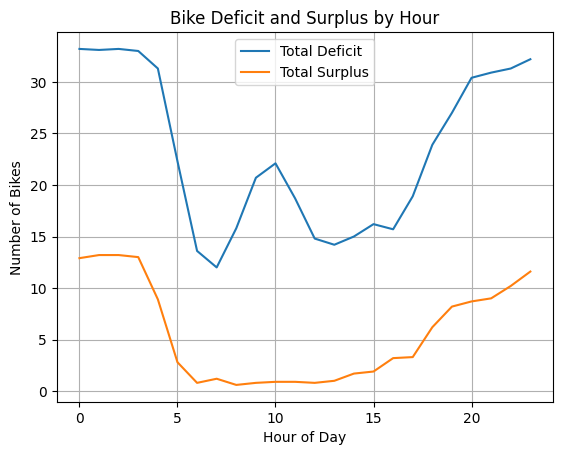

In [15]:
# ploting deficit and surplus distribution per hour

agg_hour = (
    station_hour_summary
    .groupby("hour", as_index=False)
    .agg(
        total_deficit=("deficit", "sum"),
        total_surplus=("surplus", "sum")
    )
)

import matplotlib.pyplot as plt

plt.figure()

plt.plot(agg_hour["hour"], agg_hour["total_deficit"], label="Total Deficit")
plt.plot(agg_hour["hour"], agg_hour["total_surplus"], label="Total Surplus")

plt.xlabel("Hour of Day")
plt.ylabel("Number of Bikes")
plt.title("Bike Deficit and Surplus by Hour")
plt.legend()

plt.grid(True)
plt.show()

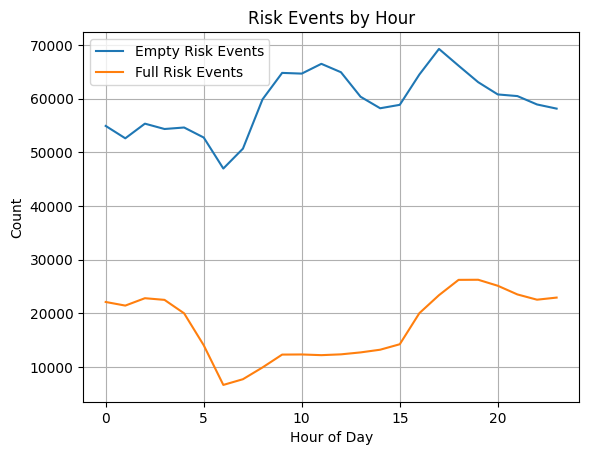

In [16]:
agg_hour_risk = (
    station_hour_summary
    .groupby("hour", as_index=False)
    .agg(
        empty_events=("n_empty_risk", "sum"),
        full_events=("n_full_risk", "sum")
    )
)


plt.figure()

plt.plot(agg_hour_risk["hour"], agg_hour_risk["empty_events"], label="Empty Risk Events")
plt.plot(agg_hour_risk["hour"], agg_hour_risk["full_events"], label="Full Risk Events")

plt.xlabel("Hour of Day")
plt.ylabel("Count")
plt.title("Risk Events by Hour")
plt.legend()

plt.grid(True)
plt.show()

<Figure size 640x480 with 0 Axes>

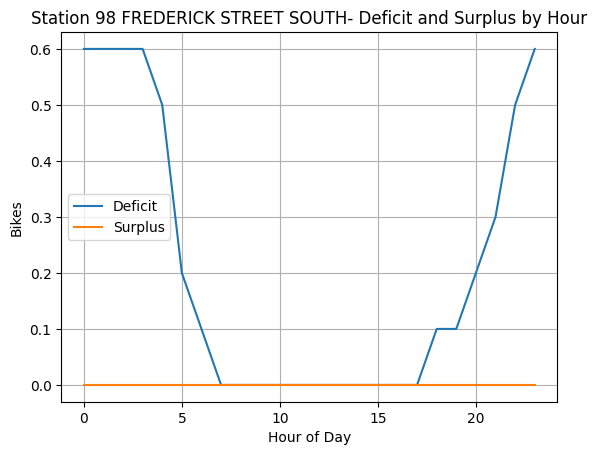

In [26]:
station_id_selected = 98

  # change this
name_col = df_test['name']

df_station = station_hour_summary[
    station_hour_summary["station_id"] == station_id_selected
].copy()

# print(df_station.head(10))
station_name = df_station['name'].iloc[0] if 'name' in df_station.columns else f"Station {station_id_selected}"

plt.figure()
import matplotlib.pyplot as plt

plt.figure()

plt.plot(df_station["hour"], df_station["deficit"], label="Deficit")
plt.plot(df_station["hour"], df_station["surplus"], label="Surplus")

plt.xlabel("Hour of Day")
plt.ylabel("Bikes")
plt.title(f"Station {station_id_selected} {station_name}- Deficit and Surplus by Hour")
plt.legend()
plt.grid(True)
plt.show()

## 12. Export clean business-facing datasets

The submission keeps only simple business outputs:
- `xgb_business_view.parquet`: row-level prediction and business interpretation
- `station_hour_risk_summary.parquet`: compact station-hour summary
- `top10_station_risk_summary.parquet`: a small example table for the report

In [27]:
business_cols = [
    "station_id",
    "last_reported",
    "hour",
    "month",
    "day",
    "weekday",
    "time",
    "capacity",
    "utilisation",
    "current_bikes",
    "true_utilisation_tplus_30",
    "pred_utilisation_tplus_30",
    "true_bikes_tplus_30",
    "pred_bikes_tplus_30",
    "true_free_docks_tplus_30",
    "pred_free_docks_tplus_30",
    "empty_risk_true",
    "empty_risk_pred",
    "full_risk_true",
    "full_risk_pred",
    "bike_deficit",
    "bike_surplus",
    "risk",
]

if name_col is not None:
    business_cols.insert(1, name_col)

business_view = df_test[business_cols].copy()

business_view.to_parquet("xgb_business_view.parquet", index=False)
station_hour_summary[summary_cols].to_parquet("station_hour_risk_summary.parquet", index=False)
top_station_risk_summary.to_parquet("top10_station_risk_summary.parquet", index=False)

print("Saved:")
print("- xgb_business_view.parquet")
print("- station_hour_risk_summary.parquet")
print("- top10_station_risk_summary.parquet")

TypeError: unhashable type: 'Series'